# Paneldata: modeller, estimation og eksperimenter

Vi starter med modellen fra slides og sammenligner pooled OLS, FD, FE og RE. Ændr parametrene i simulationskaldet og kør de efterfølgende celler igen. Til sidst reproducerer vi huspris- og politieksemplerne.

Alle stier er relative til denne notebook i `Eksempler`.


In [1]:
%matplotlib inline
import importlib
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display

panel = importlib.import_module("14_paneldata_examples")
importlib.reload(panel)

<module '14_paneldata_examples' from '/Users/fzp386/Dropbox/2Teaching/EconometricsA/2026/_PrivateRepo/1_lectures/14_paneldata/Eksempler/14_paneldata_examples.py'>

## Permanent heterogenitet og endogenitet

$$
y_{it}=1+\beta x_{it}+a_i+u_{it},\qquad
x_{it}=2+v_{it}+c\,a_i.
$$

De underliggende træk er indbyrdes uafhængige:
$$
a_i\sim N(0,\sigma_a^2),\quad
v_{it}\sim N(0,\sigma_v^2),\quad
u_{it}\sim N(0,\sigma_u^2).
$$

Her hedder $c$ `loading_a` i koden. Når $c\ne0$, påvirker permanent heterogenitet både $x$ og $y$. Streng eksogenitet i forhold til $u$ holder i denne DGP, men RE-antagelsen om $a_i$ fejler.

Simulatoren ligger i `14_paneldata_examples.py` sammen med estimations- og plotfunktionerne.


In [2]:
data = panel.simulate_panel(
    n=500, t=2, beta=2,
    sigma_a=2, sigma_v=2, sigma_u=1,
    loading_a=1, seed=117
)
data.head()

,i,t,x,y
0,0,1,2.600998,5.300745
1,0,2,5.479865,12.968442
2,1,1,3.671988,8.757075
3,1,2,3.240840,8.839023
4,2,1,-1.877361,-5.143270


## FD, within-transformation og antagelser

Vi arbejder med et **balanceret panel (balanced panel)**: De samme $n$ individer observeres i alle $T$ perioder.

Første differenser ved to perioder:
$$
\Delta y_i=\delta_0+\beta\Delta x_i+\Delta u_i.
$$

**Within-transformation / demeaning** med Wooldridges notation:
$$
\ddot y_{it}=y_{it}-\bar y_i,\quad
\ddot x_{it}=x_{it}-\bar x_i,\quad
\ddot u_{it}=u_{it}-\bar u_i.
$$
$$
\ddot y_{it}=\beta\ddot x_{it}
+\delta_0\ddot{d2}_t+\ddot u_{it}.
$$

Ved flere perioder kan tidsdummy-leddet erstattes af generelle fælles tidseffekter.

**FD.1–FD.4 og FE.1–FE.4** er de samme grundlæggende krav:

- FD.1 / FE.1: Lineær model med additive, permanente individeffekter.
- FD.2 / FE.2: Tilfældig stikprøve af individer.
- FD.3 / FE.3: Tilstrækkelig variation og ingen perfekt multikollinearitet efter transformationen og kontrol for tid.
- FD.4 / FE.4: Streng eksogenitet,
$$
E(u_{it}\mid x_{i1},\ldots,x_{iT},a_i)=0.
$$

FD.5–FD.6 vedrører variansen og seriekorrelationen i $\Delta u$; FE.5–FE.6 vedrører de oprindelige $u$. De sidste antagelser handler om standardfejl og efficiens, ikke om at fjerne $a_i$.

Prøv selv at beregne differenser og individgennemsnit, inden du bruger funktionen.


In [3]:
# Udfyld selv:
# data["dy"] = ...
# data["dx"] = ...
# data["y_within"] = ...
# data["x_within"] = ...

## OLS, FD, FE og RE

Within-transformationen følger Wooldridges notation:
$$
\ddot x_{it}=x_{it}-\bar x_i,\qquad
\ddot y_{it}=y_{it}-\bar y_i,\qquad
\ddot u_{it}=u_{it}-\bar u_i.
$$

Efter within-transformationen skal fælles tidseffekter stadig med. I et balanceret panel giver FWL:
$$
\hat\beta^{FE}
=\frac{\sum_i\sum_t(\ddot x_{it}-\overline{\ddot x}_t)
(\ddot y_{it}-\overline{\ddot y}_t)}
{\sum_i\sum_t(\ddot x_{it}-\overline{\ddot x}_t)^2}.
$$
Her er $\overline{\ddot x}_t=\frac1n\sum_i\ddot x_{it}$ og tilsvarende for $y$. Ved $T=2$ giver FE med tidsdummy samme hældning som FD med konstantled.

RE anvender **partial demeaning (quasi-demeaning)**. Her skriver vi det sammensatte fejlled direkte som $a_i+u_{it}$, så det ikke forveksles med DGP'ens regressor-chok $v_{it}$:
$$
y_{it}-\theta\bar y_i=(1-\theta)\beta_0+
\beta(x_{it}-\theta\bar x_i)+(a_i+u_{it})-\theta(a_i+\bar u_i),\quad
\theta=1-\sqrt{\frac{\sigma_u^2}{\sigma_u^2+T\sigma_a^2}}.
$$

Funktionen estimerer varianskomponenterne og beregner faktisk feasible GLS. Alle fire regressioner tillader fælles tidseffekter. Tabellen viser konventionelle modelbaserede standardfejl. FE-standardfejlen tager højde for de fjernede individparametre. OLS/RE bliver ikke gyldige, blot fordi deres standardfejl er små.


In [4]:
estimates = panel.estimate_panel(data)
display(estimates.round(4))
print(f"RE-transformation: theta = {estimates.attrs['theta']:.3f}")

,estimate,std_error
OLS,2.4959,0.0196
FD,2.0046,0.0223
FE,2.0046,0.0223
RE,2.2818,0.0196


RE-transformation: theta = 0.518


## Mange nye stikprøver

Her er OLS-grænseværdien
$$
\operatorname{plim}\hat\beta^{OLS}
=\beta+\frac{c\,\sigma_a^2}{\sigma_v^2+c^2\sigma_a^2}.
$$

Med standardparametrene giver det $2+4/8=2.5$. FD og FE fjerner $a_i$ og er konsistente under DGP'ens antagelser. Flere observationer gør fordelingen smallere, men fjerner ikke OLS-biasen.


,gennemsnit
OLS,2.5014
FD,1.9991
FE,1.9991
RE,2.3003


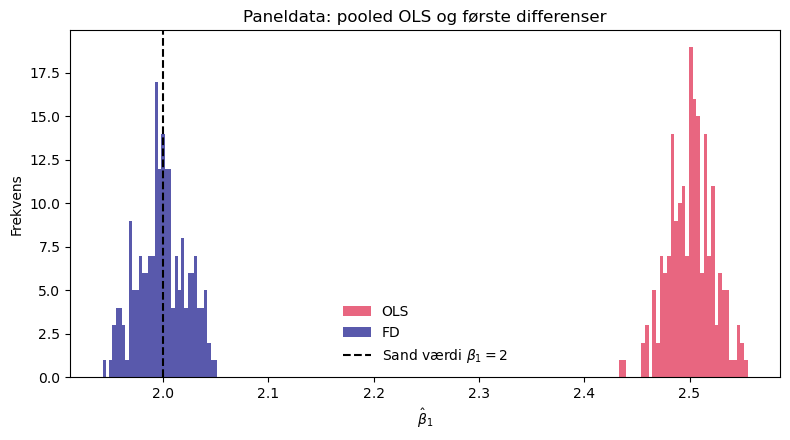

In [5]:
# Brug fx 200 gentagelser interaktivt; slidefiguren bruger 1.000.
results = panel.simulation_results(reps=200, n=500, t=2)
display(results.mean().to_frame("gennemsnit").round(4))
panel.plot_simulation(results, path=None)

## Eksperimenter

Skift ét valg i simulationskaldet og estimér igen.

- Prøv `loading_a=0`. Holder RE-antagelsen nu?
- Prøv `loading_a=-1`. Hvilket fortegn får OLS-biasen?
- Prøv større `sigma_a` eller `sigma_v`. Hvad sker der med biasen?
- Prøv større `sigma_u`. Hvad sker der med præcisionen?
- Prøv `t=5`. Giver FE og FD stadig samme estimat?
- Prøv større `n`. Forsvinder endogenitetsbiasen?

I et Monte Carlo-eksperiment skal du sende de samme ændrede parametre til `simulation_results`.


In [6]:
# Prøv fx:
# data = panel.simulate_panel(loading_a=0)
# display(panel.estimate_panel(data).round(4))

## Huspriser og beslutningen om et forbrændingsanlæg

Vi reproducerer regressionen uden ekstra kontroller fra slides:
$$
rprice_{it}=\beta_0+\delta_0y81_{it}+\beta_1nearinc_{it}
+\delta_1(y81_{it}\cdot nearinc_{it})+u_{it}.
$$

Udfaldet er real huspris i **tusinde 1978-dollars**, ikke logaritmen til huspris. DiD-estimatet er koefficienten til `did`. Under parallelle kontrafaktiske trends er det effekten af beslutningen om anlægget.
Tabellens standardfejl er konventionelle, så de matcher Wooldridge. Prøv `cov_type="HC1"` i funktionskaldet for at sammenligne med heteroskedasticitetsrobuste standardfejl.


In [7]:
did = panel.difference_in_differences()
did.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 rprice   R-squared:                       0.174
Model:                            OLS   Adj. R-squared:                  0.166
Method:                 Least Squares   F-statistic:                     22.25
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           4.22e-13
Time:                        00:29:21   Log-Likelihood:                -1547.8
No. Observations:                 321   AIC:                             3104.
Df Residuals:                     317   BIC:                             3119.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         82.5172      2.727     30.260      0.000      77.152      87.882
y81           18.7903      4.050      4.640      0.000      10.822      26.759
nearinc      -18.8244      4.875     -3.861      0.000     -28.416      -9.232
did          -11.8639      7.457     -1.591      0.113     -26.535       2.807
==============================================================================
Omnibus:                      192.562   Durbin-Watson:                   1.557
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2462.070
Skew:                           2.217   Prob(JB):                         0.00
Kurtosis:                      15.822   Cond. No.                         6.05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Politibeskyttelse og biltyverier

Vi beregner først gennemsnitligt antal tyverier for hver blok i april–juni og august–oktober. Vi bruger ikke blot første måned i hver periode.

$$
\Delta biltyverier_i=\beta_2+\beta_3institution_i+\Delta u_i.
$$

FD og DiD giver samme punktestimat. Deres almindelige robuste standardfejl kan være forskellige, fordi DiD har to afhængige observationer pr. blok. Grupperede DiD-standardfejl på blokniveau ligger tæt på FD-standardfejlene. Grupperede standardfejl er ud over pensum.


In [8]:
police_did, police_fd = panel.police_difference_in_differences()
display(pd.DataFrame({
    "estimate": [police_did.params["post_institu1"], police_fd.params["institu1"]],
    "robust SE": [police_did.bse["post_institu1"], police_fd.bse["institu1"]]
}, index=["DiD", "FD"]).round(4))

,estimate,robust SE
DiD,-0.0903,0.0369
FD,-0.0903,0.0334
